# NHANES 15 chỉ số — mở rộng 5 chu kỳ (2011–2023)

Nâng cấp notebook 04 (chỉ 2 chu kỳ, train 2015–16). Tải thêm các chu kỳ công khai của CDC: **2011–2012 (G), 2013–2014 (H)** và **2021–2023 (L)**.

- Train/validation: 2011–2016 (G, H, I), chia theo cụm khảo sát (chu kỳ + tầng + PSU) để tránh rò rỉ.
- Test: 2017–2018 (J) — cùng tập test với notebook 04 để so sánh trực tiếp.
- Test ngoài: 2021–2023 (L) — dữ liệu sau COVID, huyết áp đo bằng máy tự động (khác phương pháp), dùng để kiểm tra độ bền theo thời gian.

Nhãn DIQ010 là tự khai từng được thông báo mắc đái tháo đường; glucose/HbA1c có thể đã dùng để chẩn đoán trước đó. Không phải chẩn đoán hay dự báo mắc mới; không phải dữ liệu Việt Nam.

## 1. Thiết lập
Chọn dữ liệu, cấu hình và đường dẫn. Mỗi lần chạy tạo một thư mục mới trong `artifacts/notebook_runs/`.

In [1]:
EXPERIMENT = 'nhanes15_multi'
MODEL_TYPE = 'CNN'
PURPOSE = 'NHANES 2011–2016 train, 2017–2018 test, 2021–2023 test ngoài; 15 chỉ số; nhãn tự khai DIQ010.'
import os, json, hashlib, random, sys, platform
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, brier_score_loss)
import torch
from torch import nn
import joblib
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'docker-compose.yml').exists()), None)
if ROOT is None: raise RuntimeError('Chạy notebook trong thư mục dự án.')
SMOKE = os.getenv('NOTEBOOK_SMOKE') == '1'  # Chỉ dùng cho kiểm thử kỹ thuật, không báo cáo kết quả.
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(1)
run_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR = (Path('/tmp/duongan_notebook_smoke') if SMOKE else ROOT/'artifacts/notebook_runs') / EXPERIMENT / run_stamp
RUN_DIR.mkdir(parents=True, exist_ok=False)
print('Project:', ROOT, '| kết quả:', RUN_DIR, '| kiểm thử nhanh:', SMOKE)

Project: /Users/handq2212/DaiHoc/Nam4/LTHTTM/project | kết quả: /Users/handq2212/DaiHoc/Nam4/LTHTTM/project/artifacts/notebook_runs/nhanes15_multi/20261112T073408_304203Z | kiểm thử nhanh: False


## 2. Đọc và biểu diễn dữ liệu
Đọc dữ liệu gốc và kiểm tra số dòng, cột. Các biểu đồ phân tích chi tiết ở mục 4 chỉ dùng tập train.

In [2]:
features = ['RIDAGEYR','RIAGENDR','BMXBMI','BMXWAIST','BPXSY1','BPXDI1','LBXGLU','LBXGH','LBXTC','LBDHDD','LBXTR','LBXSATSI','LBXSCR','BMXWT','BMXHT']
numeric, categorical = features, []
FEATURE_DESCRIPTIONS = {'RIDAGEYR':'Tuổi (năm)','RIAGENDR':'Giới (1 nam, 2 nữ)','BMXBMI':'BMI (kg/m²)','BMXWAIST':'Vòng eo (cm)',
  'BPXSY1':'Huyết áp tâm thu lần 1 (mmHg)','BPXDI1':'Huyết áp tâm trương lần 1 (mmHg)','LBXGLU':'Glucose huyết tương lúc đói (mg/dL)',
  'LBXGH':'HbA1c (%)','LBXTC':'Cholesterol toàn phần (mg/dL)','LBDHDD':'HDL (mg/dL)','LBXTR':'Triglyceride (mg/dL)',
  'LBXSATSI':'ALT (U/L)','LBXSCR':'Creatinine huyết thanh (mg/dL)','BMXWT':'Cân nặng (kg)','BMXHT':'Chiều cao (cm)'}
columns = {
 'DEMO':['SEQN','RIDAGEYR','RIAGENDR','SDMVSTRA','SDMVPSU'], 'DIQ':['SEQN','DIQ010'],
 'BMX':['SEQN','BMXBMI','BMXWAIST','BMXWT','BMXHT'], 'BPX':['SEQN','BPXSY1','BPXDI1'],
 'GLU':['SEQN','LBXGLU'], 'GHB':['SEQN','LBXGH'], 'TCHOL':['SEQN','LBXTC'],
 'HDL':['SEQN','LBDHDD'], 'TRIGLY':['SEQN','LBXTR'], 'BIOPRO':['SEQN','LBXSATSI','LBXSCR']}
# Chu kỳ 2021–2023 (_L): huyết áp đo bằng máy dao động tự động (BPXO) thay cho đo thủ công,
# triglyceride đổi tên LBXTLG. Đổi tên về cùng tên biến nhưng phương pháp đo KHÁC — chỉ dùng làm test ngoài.
CYCLE_FILES = {'L': {'BPX': ('BPXO', {'BPXOSY1': 'BPXSY1', 'BPXODI1': 'BPXDI1'}), 'TRIGLY': ('TRIGLY', {'LBXTLG': 'LBXTR'})}}
CYCLES = {'G': '2011–2012', 'H': '2013–2014', 'I': '2015–2016', 'J': '2017–2018', 'L': '2021–2023'}
TRAIN_CYCLES, TEST_CYCLE, EXTERNAL_CYCLE = ['G', 'H', 'I'], 'J', 'L'
EXTRA_REPORT = {'cycles': CYCLES, 'train_validation_cycles': TRAIN_CYCLES, 'test_cycle': TEST_CYCLE, 'external_test_cycle': EXTERNAL_CYCLE}
source_paths = []
def read_cycle(suffix):
    frames=[]
    for name, cols in columns.items():
        file_name, renames = CYCLE_FILES.get(suffix, {}).get(name, (name, {}))
        path=ROOT/f'data/raw/nhanes/{file_name}_{suffix}.xpt'; source_paths.append(path)
        f=pd.read_sas(path,format='xport').rename(columns=renames)[cols]
        if f.SEQN.duplicated().any(): raise ValueError(f'Trùng SEQN: {path}')
        frames.append(f)
    df=frames[0]
    for f in frames[1:]: df=df.merge(f,on='SEQN',how='left',validate='one_to_one')
    df['cycle']=suffix
    return df
raw = {s: read_cycle(s) for s in TRAIN_CYCLES + [TEST_CYCLE, EXTERNAL_CYCLE]}
print('Số dòng gốc theo chu kỳ:', {CYCLES[s]: len(df) for s, df in raw.items()})

Số dòng gốc theo chu kỳ: {'2011–2012': 9756, '2013–2014': 10175, '2015–2016': 9971, '2017–2018': 9254, '2021–2023': 11933}


## 3. Làm sạch, định nghĩa nhãn và chia tập
Loại nhãn không hợp lệ, kiểm soát dữ liệu thiếu và tách test. Các phép học tham số xử lý dữ liệu chỉ được fit sau khi chia tập.

In [3]:
def clean_cycle(raw):
    df=raw[(raw.RIDAGEYR>=18)&raw.DIQ010.isin([1,2])].copy()
    for col in ['BPXSY1','BPXDI1']:
        if col in df: df.loc[df[col] <= 0,col] = np.nan
    df = df.dropna(subset=features+['SDMVSTRA','SDMVPSU']).copy()
    df['class'] = (df.DIQ010 == 1).astype(int)
    # Nhóm theo chu kỳ + tầng + PSU để train/validation không chia cắt cùng một cụm khảo sát.
    df['group'] = df.cycle+'_'+df.SDMVSTRA.astype(str)+'_'+df.SDMVPSU.astype(str)
    return df
cleaned = {s: clean_cycle(df) for s, df in raw.items()}
old = pd.concat([cleaned[s] for s in TRAIN_CYCLES], ignore_index=True)
test, external = cleaned[TEST_CYCLE], cleaned[EXTERNAL_CYCLE]
all_seqn = [set(df.SEQN) for df in cleaned.values()]
if sum(len(s) for s in all_seqn) != len(set().union(*all_seqn)): raise ValueError('SEQN trùng giữa các chu kỳ; cần kiểm tra.')
indices = GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=SEED)
a,b = next(indices.split(old,old['class'],groups=old.group))
train,val = old.iloc[a].copy(),old.iloc[b].copy()
assert set(train.group).isdisjoint(set(val.group))
print('Mẫu đủ 15 chỉ số theo chu kỳ:', {CYCLES[s]: (len(df), int(df['class'].sum())) for s, df in cleaned.items()}, '(tổng, số nhãn 1)')
print('Train+validation (2011–2016):', len(old), '| test 2017–2018:', len(test), '| test ngoài 2021–2023:', len(external))

Mẫu đủ 15 chỉ số theo chu kỳ: {'2011–2012': (2209, 273), '2013–2014': (2305, 254), '2015–2016': (2094, 307), '2017–2018': (2038, 334), '2021–2023': (2843, 382)} (tổng, số nhãn 1)
Train+validation (2011–2016): 6608 | test 2017–2018: 2038 | test ngoài 2021–2023: 2843


## 4. Biểu diễn và phân tích dữ liệu train
Kiểm tra phân bố nhãn, thiếu dữ liệu, thống kê, histogram theo nhãn và tương quan các biến số. Mẫu hiển thị có thể được giới hạn để vẽ nhanh; huấn luyện dùng toàn bộ tập train.

train: 5265 mẫu; nhãn: {0: 4613, 1: 652}
validation: 1343 mẫu; nhãn: {0: 1161, 1: 182}
test: 2038 mẫu; nhãn: {0: 1704, 1: 334}

Thiếu dữ liệu trên train (%):
RIDAGEYR    0.0
RIAGENDR    0.0
BMXBMI      0.0
BMXWAIST    0.0
BPXSY1      0.0
BPXDI1      0.0
LBXGLU      0.0
LBXGH       0.0
LBXTC       0.0
LBDHDD      0.0
LBXTR       0.0
LBXSATSI    0.0
LBXSCR      0.0
BMXWT       0.0
BMXHT       0.0

Thống kê biến số trên train:
       RIDAGEYR  RIAGENDR   BMXBMI  BMXWAIST   BPXSY1   BPXDI1   LBXGLU    LBXGH    LBXTC   LBDHDD    LBXTR  LBXSATSI   LBXSCR    BMXWT    BMXHT
count   5265.00   5265.00  5265.00   5265.00  5265.00  5265.00  5265.00  5265.00  5265.00  5265.00  5265.00   5265.00  5265.00  5265.00  5265.00
mean      47.14      1.51    28.74     98.25   122.75    69.00   108.16     5.76   188.27    53.93   118.56     24.85     0.88    80.59   167.21
std       18.19      0.50     6.79     16.54    18.11    12.51    35.03     1.13    41.27    16.05   109.58     17.81     0.43    21.11  

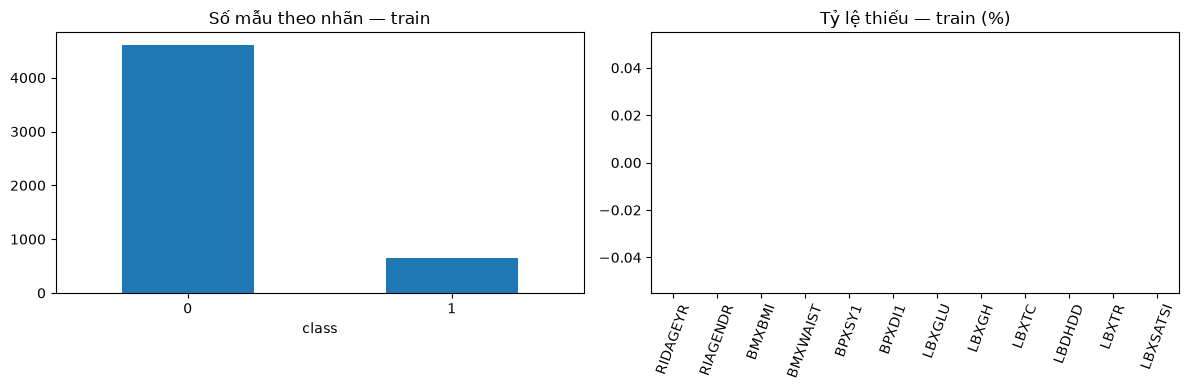

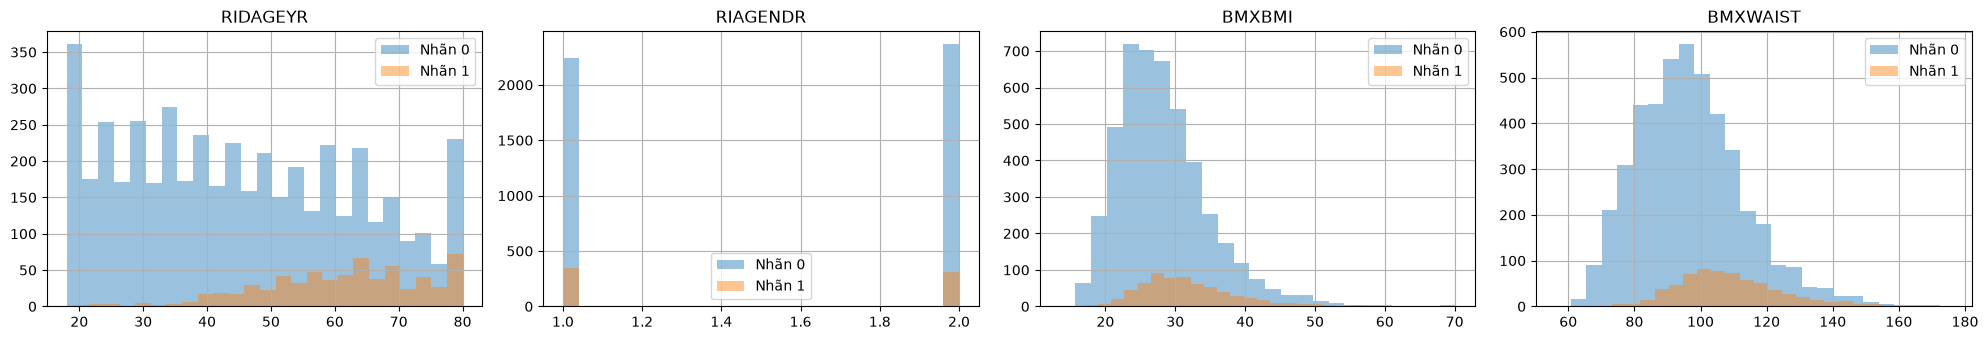

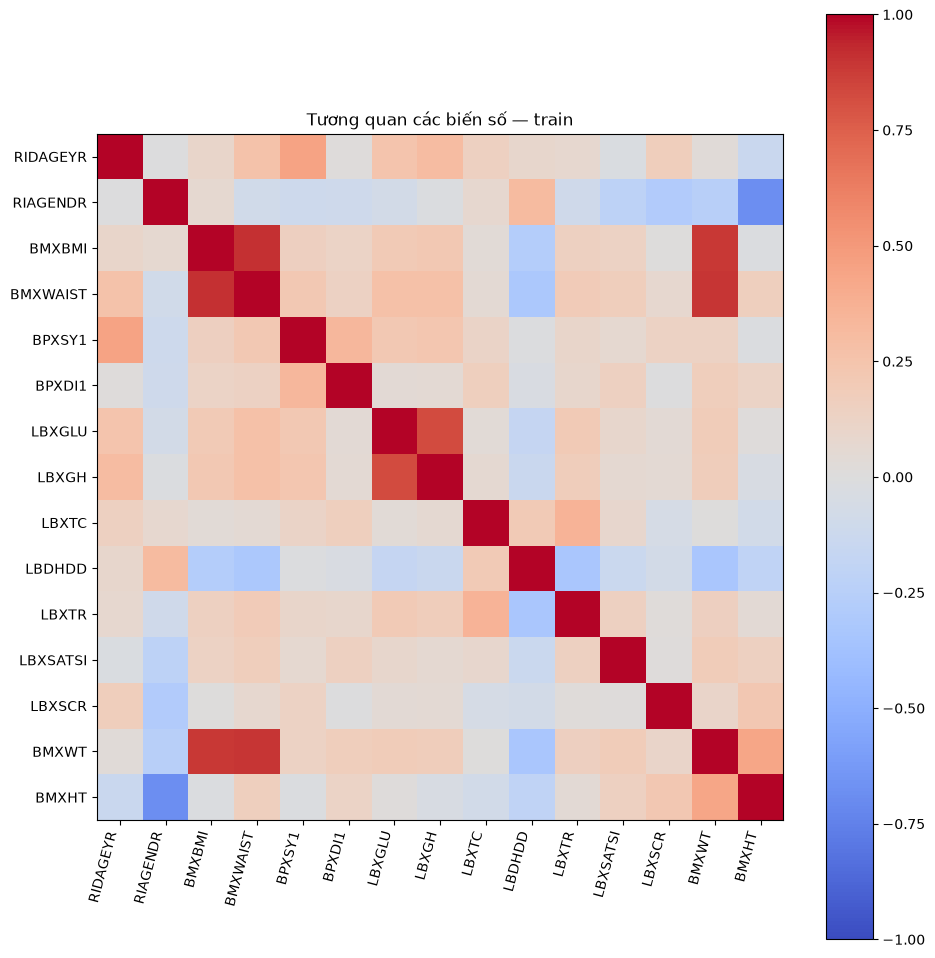

In [4]:
# Phân tích trên tập train để không dùng test quyết định đặc trưng.
for name, frame in [('train',train),('validation',val),('test',test)]:
    counts = frame['class'].value_counts().sort_index().to_dict()
    print(f'{name}: {len(frame)} mẫu; nhãn: {counts}')
    if frame['class'].nunique() != 2: raise ValueError(f'{name} cần đủ hai lớp')
print('\nThiếu dữ liệu trên train (%):')
print((train[features].isna().mean().sort_values(ascending=False)*100).round(2).to_string())
print('\nThống kê biến số trên train:')
print(train[numeric].describe().round(2).to_string())
fig,axes=plt.subplots(1,2,figsize=(12,4))
train['class'].value_counts().sort_index().plot.bar(ax=axes[0],title='Số mẫu theo nhãn — train',rot=0)
(train[features].isna().mean()*100).sort_values(ascending=False).head(12).plot.bar(ax=axes[1],title='Tỷ lệ thiếu — train (%)',rot=70)
plt.tight_layout(); plt.show()
# Số mẫu lớn chỉ lấy tối đa 10.000 điểm train cho biểu đồ, không thay đổi dữ liệu huấn luyện.
visual=train.sample(n=min(10000,len(train)),random_state=SEED)
plot_cols=numeric[:min(4,len(numeric))]
fig,axes=plt.subplots(1,len(plot_cols),figsize=(5*len(plot_cols),3.5),squeeze=False)
for ax,col in zip(axes[0],plot_cols):
    for label in (0,1):
        visual.loc[visual['class']==label,col].dropna().hist(ax=ax,bins=25,alpha=.45,label=f'Nhãn {label}')
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()
if len(numeric)>1:
    corr=visual[numeric].corr(numeric_only=True)
    fig,ax=plt.subplots(figsize=(max(6,len(corr)*.65),max(5,len(corr)*.65)))
    im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
    ax.set_xticks(range(len(corr)),corr.columns,rotation=75,ha='right'); ax.set_yticks(range(len(corr)),corr.index)
    ax.set_title('Tương quan các biến số — train'); fig.colorbar(im,ax=ax); plt.tight_layout(); plt.show()

## 5. Tiền xử lý
Điền khuyết và chuẩn hóa trên train; biến phân loại one-hot. Áp dụng các phép biến đổi đã học lên validation/test.

In [5]:
def frame_x(frame):
    x=frame[features].copy()
    for col in categorical: x[col]=x[col].astype(object).where(x[col].notna(),np.nan)
    return x
parts=[]
if numeric: parts.append(('num',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),numeric))
if categorical: parts.append(('cat',make_pipeline(SimpleImputer(strategy='most_frequent'),OneHotEncoder(handle_unknown='ignore')),categorical))
preprocessor=ColumnTransformer(parts,sparse_threshold=0)
Xtr=preprocessor.fit_transform(frame_x(train)).astype('float32')
Xva=preprocessor.transform(frame_x(val)).astype('float32')
Xte=preprocessor.transform(frame_x(test)).astype('float32')
ytr,yva,yte=[f['class'].to_numpy(dtype='float32') for f in (train,val,test)]
print('Kích thước sau tiền xử lý:',Xtr.shape,Xva.shape,Xte.shape)

Kích thước sau tiền xử lý: (5265, 15) (1343, 15) (2038, 15)


## 6. Định nghĩa mô hình và baseline
Mạng nơ-ron so sánh với Dummy, Logistic Regression và HistGradientBoosting. CNN 1D trên dữ liệu bảng là giả định thực nghiệm về thứ tự cột.

In [6]:
# So sánh với baseline đơn giản và mô hình phi tuyến trên cùng dữ liệu.
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve
class Net(nn.Module):
    def __init__(self,n):
        super().__init__()
        if MODEL_TYPE=='MLP':
            self.net=nn.Sequential(nn.Linear(n,64),nn.ReLU(),nn.Dropout(.2),nn.Linear(64,32),nn.ReLU(),nn.Linear(32,1))
        else:
            self.net=nn.Sequential(nn.Unflatten(1,(1,n)),nn.Conv1d(1,16,3,padding=1),nn.ReLU(),nn.Conv1d(16,32,3,padding=1),nn.ReLU(),nn.MaxPool1d(2),nn.Flatten(),nn.Linear(32*(n//2),32),nn.ReLU(),nn.Dropout(.2),nn.Linear(32,1))
    def forward(self,x): return self.net(x).squeeze(-1)
print('Kiến trúc ứng viên:'); print(Net(Xtr.shape[1]))
print('So sánh thêm: Dummy prior, Logistic Regression, HistGradientBoosting.')

Kiến trúc ứng viên:
Net(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(1, 15))
    (1): Conv1d(1, 16, kernel_size=(3,), stride=(1,), padding=(1,))
    (2): ReLU()
    (3): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=224, out_features=32, bias=True)
    (8): ReLU()
    (9): Dropout(p=0.2, inplace=False)
    (10): Linear(in_features=32, out_features=1, bias=True)
  )
)
So sánh thêm: Dummy prior, Logistic Regression, HistGradientBoosting.


## 7. Huấn luyện và kiểm tra hội tụ
Tối đa 200 epoch, tối thiểu 40 epoch và dừng sớm nếu validation loss không cải thiện trong 25 epoch. Chạy ba seed khởi tạo; đồ thị hiển thị train/validation loss, epoch tốt nhất và số bước cập nhật. Seed chỉ đo độ nhạy khởi tạo, không thay thế kiểm định trên nhiều tập chia độc lập.

Training dummy


Training logistic_regression


Training hist_gradient_boosting


seed=42: epochs=40, best=3, updates=3320, val AUC=0.9301, early_stop=True


seed=43: epochs=40, best=4, updates=3320, val AUC=0.9340, early_stop=True


seed=44: epochs=40, best=3, updates=3320, val AUC=0.9341, early_stop=True


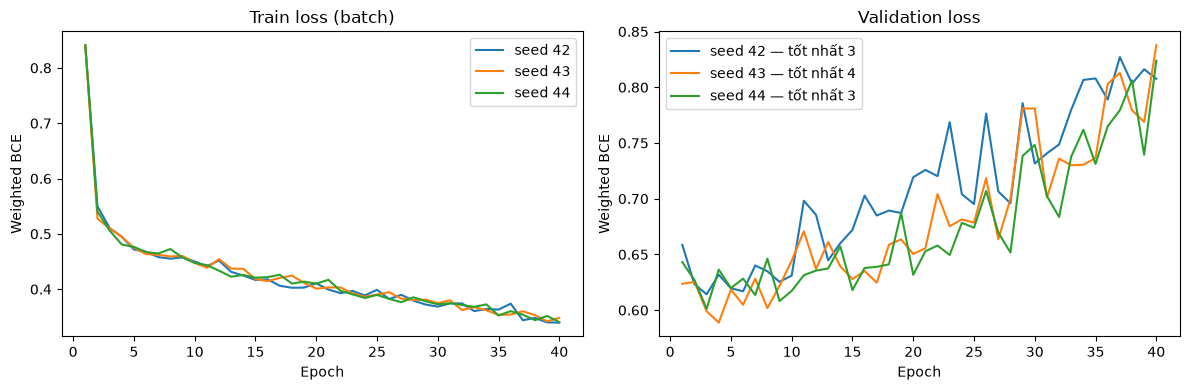

Dao động validation AUC giữa các seed: [0.9301, 0.934, 0.9341]


In [7]:
# Cùng tập train/validation cho tất cả ứng viên. Ba seed chỉ thay đổi khởi tạo,
# không thay thế việc đánh giá trên nhiều phép chia dữ liệu độc lập.
from copy import deepcopy
candidates = {
    'dummy':DummyClassifier(strategy='prior'),
    'logistic_regression':LogisticRegression(max_iter=1000,class_weight='balanced',random_state=SEED),
    'hist_gradient_boosting':HistGradientBoostingClassifier(max_iter=100 if not SMOKE else 5,max_leaf_nodes=15,class_weight='balanced',random_state=SEED),
}
for name, estimator in candidates.items():
    print('Training',name,flush=True); estimator.fit(Xtr,ytr)

seeds=[42] if SMOKE else [42,43,44]
max_epochs=2 if SMOKE else 200
min_epochs=1 if SMOKE else 40
patience_limit=2 if SMOKE else 25
# Batch lớn giúp bộ BRFSS khả thi; số lần cập nhật thực tế được lưu trong report.
batch_size=4096 if EXPERIMENT.startswith('brfss') else 64
xt,yt=torch.tensor(Xtr),torch.tensor(ytr)
xv,yv=torch.tensor(Xva),torch.tensor(yva)
pos_weight=torch.tensor([(len(ytr)-sum(ytr))/sum(ytr)],dtype=torch.float32)
loss_fn=nn.BCEWithLogitsLoss(pos_weight=pos_weight)
runs=[]
for run_seed in seeds:
    torch.manual_seed(run_seed); random.seed(run_seed); np.random.seed(run_seed)
    model=Net(Xtr.shape[1]); optimizer=torch.optim.Adam(model.parameters(),lr=0.001)
    generator=torch.Generator().manual_seed(run_seed)
    loader=torch.utils.data.DataLoader(torch.utils.data.TensorDataset(xt,yt),batch_size=batch_size,shuffle=True,generator=generator)
    best_loss=float('inf'); best_state=None; best_epoch=0; patience=0; history=[]; updates=0
    for epoch in range(1,max_epochs+1):
        model.train(); total_loss=0.0
        for x,y in loader:
            optimizer.zero_grad(); loss=loss_fn(model(x),y); loss.backward(); optimizer.step()
            total_loss+=float(loss.detach())*len(y); updates+=1
        model.eval()
        with torch.no_grad(): val_loss=float(loss_fn(model(xv),yv))
        history.append({'epoch':epoch,'train_loss':total_loss/len(ytr),'val_loss':val_loss})
        if val_loss < best_loss - 1e-4:
            best_loss=val_loss; best_epoch=epoch; best_state=deepcopy(model.state_dict()); patience=0
        else: patience+=1
        if epoch>=min_epochs and patience>=patience_limit: break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad(): valid_scores=torch.sigmoid(model(xv)).numpy()
    run={'seed':run_seed,'model':model,'best_epoch':best_epoch,'epochs_run':len(history),
         'updates':updates,'stopped_early':len(history)<max_epochs,'history':history,
         'val_scores':valid_scores,'val_auc':float(roc_auc_score(yva,valid_scores))}
    runs.append(run)
    print(f"seed={run_seed}: epochs={len(history)}, best={best_epoch}, updates={updates}, val AUC={run['val_auc']:.4f}, early_stop={run['stopped_early']}",flush=True)

fig,axes=plt.subplots(1,2,figsize=(12,4))
for run in runs:
    curve=pd.DataFrame(run['history'])
    axes[0].plot(curve.epoch,curve.train_loss,label=f"seed {run['seed']}")
    axes[1].plot(curve.epoch,curve.val_loss,label=f"seed {run['seed']} — tốt nhất {run['best_epoch']}")
for ax,title in zip(axes,['Train loss (batch)','Validation loss']): ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_ylabel('Weighted BCE'); ax.legend()
plt.tight_layout(); plt.show()
print('Dao động validation AUC giữa các seed:',[round(r['val_auc'],4) for r in runs])

## 8. So sánh và lựa chọn trên validation
Bảng so sánh ROC-AUC, PR-AUC, precision, recall, F1; chọn ứng viên theo ROC-AUC validation, sau đó chọn ngưỡng theo F1 validation. Test không tham gia lựa chọn.

Bảng validation (ngưỡng tham khảo 0.5):
                        roc_auc  pr_auc  precision  recall      f1
hist_gradient_boosting   0.9407  0.8038     0.6837  0.8077  0.7406
logistic_regression      0.9347  0.7598     0.5789  0.8462  0.6875
neural_seed_44           0.9341  0.7592     0.4805  0.8791  0.6214
neural_seed_43           0.9340  0.7752     0.5333  0.8791  0.6639
neural_seed_42           0.9301  0.7577     0.5351  0.8791  0.6653
dummy                    0.5000  0.1355     0.0000  0.0000  0.0000
Chọn theo validation ROC-AUC: hist_gradient_boosting | ngưỡng F1 trên validation: 0.7
 threshold  precision  recall     f1
      0.05     0.3366  0.9396 0.4957
      0.10     0.4108  0.9231 0.5685
      0.15     0.4670  0.8956 0.6139
      0.20     0.5111  0.8846 0.6479
      0.25     0.5445  0.8736 0.6709
      0.30     0.5766  0.8681 0.6930
      0.35     0.6071  0.8407 0.7051
      0.40     0.6456  0.8407 0.7303
      0.45     0.6637  0.8132 0.7309
      0.50     0.6837  0.8077 0.740

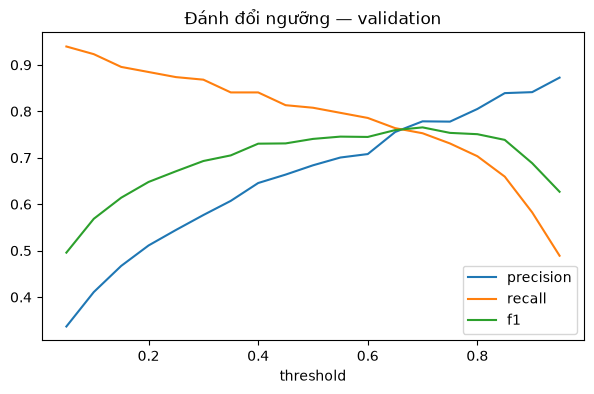

In [8]:
# So sánh validation theo nhiều chỉ số. AUC quyết định mô hình; ngưỡng F1 được chọn riêng trên validation.
val_scores={name:est.predict_proba(Xva)[:,1] for name,est in candidates.items()}
for run in runs: val_scores[f"neural_seed_{run['seed']}"]=run['val_scores']
def threshold_scores(y, scores, threshold):
    pred=(scores>=threshold).astype(int)
    return {'roc_auc':float(roc_auc_score(y,scores)),'pr_auc':float(average_precision_score(y,scores)),
            'precision':float(precision_score(y,pred,zero_division=0)),'recall':float(recall_score(y,pred,zero_division=0)),
            'f1':float(f1_score(y,pred,zero_division=0))}
validation_table=pd.DataFrame({name:threshold_scores(yva,s,.5) for name,s in val_scores.items()}).T.sort_values('roc_auc',ascending=False)
print('Bảng validation (ngưỡng tham khảo 0.5):'); print(validation_table.round(4).to_string())
# Nếu bằng AUC, ưu tiên baseline đơn giản theo thứ tự khai báo.
priority=list(val_scores)
selected=max(priority,key=lambda name:roc_auc_score(yva,val_scores[name]))
threshold_grid=np.round(np.linspace(.05,.95,19),2)
threshold_table=pd.DataFrame([{'threshold':float(t),**threshold_scores(yva,val_scores[selected],t)} for t in threshold_grid])
selected_threshold=float(threshold_table.loc[threshold_table.f1.idxmax(),'threshold'])
print('Chọn theo validation ROC-AUC:',selected,'| ngưỡng F1 trên validation:',selected_threshold)
print(threshold_table[['threshold','precision','recall','f1']].round(4).to_string(index=False))
threshold_table.plot(x='threshold',y=['precision','recall','f1'],title='Đánh đổi ngưỡng — validation',figsize=(7,4));plt.show()
# Ngưỡng F1 là lựa chọn thực nghiệm, không phải ngưỡng lâm sàng.

## 9. Đánh giá test của mô hình đã chọn
Bảng chỉ số, báo cáo phân loại, ROC, Precision–Recall, ma trận nhầm lẫn và khoảng bootstrap phân tầng. Đây là đánh giá học thuật không trọng số; tập test đã từng được sử dụng trong các lần chạy trước và không còn hoàn toàn độc lập.

Kết quả test CHỈ của ứng viên được chọn:
{
  "roc_auc": 0.9468158752916702,
  "pr_auc": 0.8217832176922354,
  "precision": 0.7831325301204819,
  "recall": 0.7784431137724551,
  "f1": 0.7807807807807807,
  "accuracy": 0.9283611383709519,
  "brier": 0.06943740772732182,
  "confusion_matrix": [
    [
      1632,
      72
    ],
    [
      74,
      260
    ]
  ]
}
Báo cáo phân loại:
              precision    recall  f1-score   support

         0.0       0.96      0.96      0.96      1704
         1.0       0.78      0.78      0.78       334

    accuracy                           0.93      2038
   macro avg       0.87      0.87      0.87      2038
weighted avg       0.93      0.93      0.93      2038



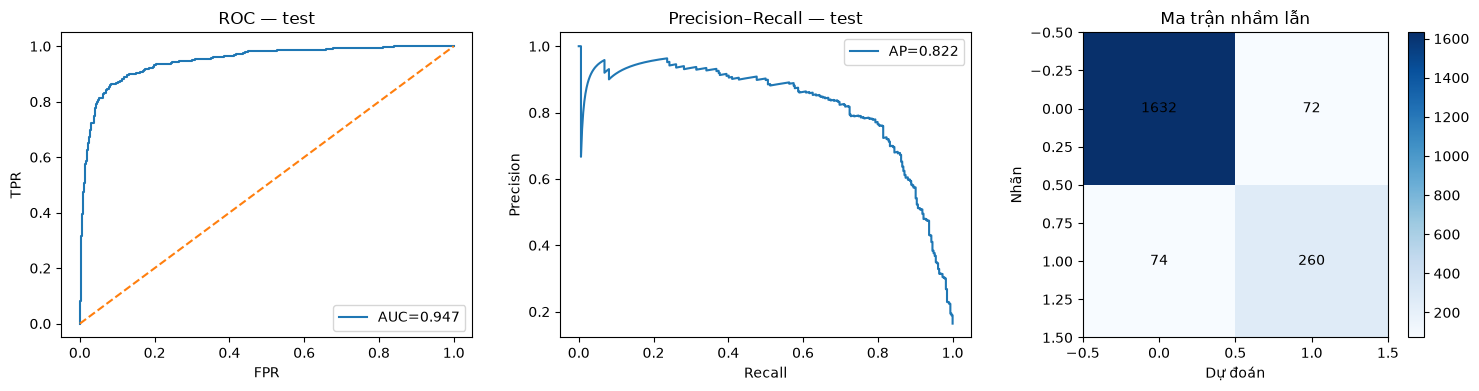

Khoảng bootstrap phân tầng 95% cho ROC-AUC (không tính thiết kế khảo sát): [0.9334881293750527, 0.9583338165218858]
Lưu ý: dữ liệu test đã từng được xem trong các lần chạy trước; đây không còn là kiểm định cuối hoàn toàn độc lập.


In [9]:
if selected.startswith('neural_seed_'):
    best_run=next(r for r in runs if selected==f"neural_seed_{r['seed']}")
    best_run['model'].eval()
    with torch.no_grad(): test_scores=torch.sigmoid(best_run['model'](torch.tensor(Xte))).numpy()
else: test_scores=candidates[selected].predict_proba(Xte)[:,1]
pred=(test_scores>=selected_threshold).astype(int)
test_metrics={**threshold_scores(yte,test_scores,selected_threshold),
    'accuracy':float(accuracy_score(yte,pred)),'brier':float(brier_score_loss(yte,test_scores)),
    'confusion_matrix':confusion_matrix(yte,pred,labels=[0,1]).tolist()}
print('Kết quả test CHỈ của ứng viên được chọn:'); print(json.dumps(test_metrics,indent=2))
print('Báo cáo phân loại:');print(classification_report(yte,pred,zero_division=0))
fpr,tpr,_=roc_curve(yte,test_scores); prec,rec,_=precision_recall_curve(yte,test_scores)
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].plot(fpr,tpr,label=f"AUC={test_metrics['roc_auc']:.3f}");axes[0].plot([0,1],[0,1],'--');axes[0].set(xlabel='FPR',ylabel='TPR',title='ROC — test');axes[0].legend()
axes[1].plot(rec,prec,label=f"AP={test_metrics['pr_auc']:.3f}");axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–Recall — test');axes[1].legend()
cm=np.array(test_metrics['confusion_matrix']); im=axes[2].imshow(cm,cmap='Blues'); axes[2].set(xlabel='Dự đoán',ylabel='Nhãn',title='Ma trận nhầm lẫn')
for (i,j),value in np.ndenumerate(cm): axes[2].text(j,i,str(value),ha='center',va='center')
fig.colorbar(im,ax=axes[2]);plt.tight_layout();plt.show()
# Bootstrap phân tầng, cố định số lượng mỗi lớp: khoảng mô tả có điều kiện theo mẫu test.
rng=np.random.default_rng(SEED); neg=np.flatnonzero(yte==0); pos=np.flatnonzero(yte==1)
bootstrap=[]
for _ in range(10 if SMOKE else 100):
    ix=np.concatenate([rng.choice(neg,len(neg),replace=True),rng.choice(pos,len(pos),replace=True)])
    bootstrap.append(roc_auc_score(yte[ix],test_scores[ix]))
auc_ci=np.quantile(bootstrap,[.025,.975]).tolist()
print('Khoảng bootstrap phân tầng 95% cho ROC-AUC (không tính thiết kế khảo sát):',auc_ci)
print('Lưu ý: dữ liệu test đã từng được xem trong các lần chạy trước; đây không còn là kiểm định cuối hoàn toàn độc lập.')

## 9b. Độ quan trọng đặc trưng
Mô hình đã chọn dựa vào biến nào nhiều nhất? Đo trên validation, không dùng test.

ROC-AUC gốc trên mẫu validation: 0.9407
LBXGH       0.1296
LBXGLU      0.0196
RIDAGEYR    0.0110
LBXTC       0.0088
LBXSATSI    0.0038
LBXTR       0.0024
LBXSCR      0.0022
BMXBMI      0.0016
BMXWAIST    0.0012
BMXWT       0.0003
RIAGENDR   -0.0002
BPXDI1     -0.0007
BPXSY1     -0.0007
BMXHT      -0.0010
LBDHDD     -0.0014


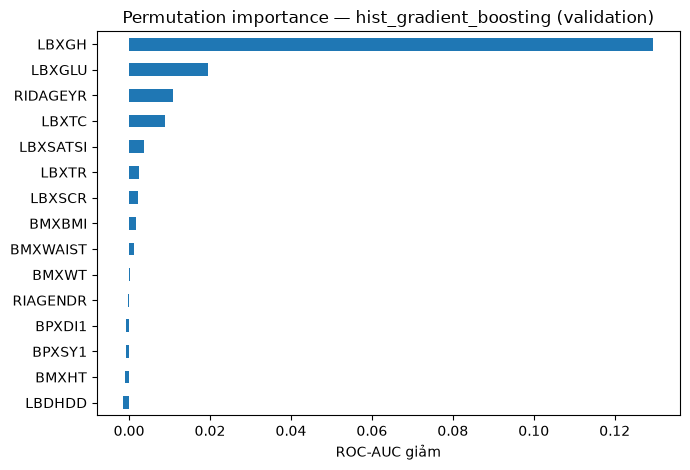

In [10]:
# Độ quan trọng đặc trưng (permutation importance) trên VALIDATION cho mô hình đã chọn.
# Xáo trộn từng cột gốc rồi đo ROC-AUC giảm bao nhiêu: giảm càng nhiều, mô hình càng dựa vào biến đó.
# Đây là mức độ mô hình sử dụng biến, KHÔNG phải quan hệ nhân quả.
def score_frame(frame):
    X = preprocessor.transform(frame_x(frame)).astype('float32')
    if selected.startswith('neural_seed_'):
        with torch.no_grad(): return torch.sigmoid(best_run['model'](torch.tensor(X))).numpy()
    return candidates[selected].predict_proba(X)[:, 1]
if selected.startswith('neural_seed_'):
    best_run = next(r for r in runs if selected == f"neural_seed_{r['seed']}")
sample = val.sample(n=min(20000, len(val)), random_state=SEED)
y_sample = sample['class'].to_numpy()
base_auc = roc_auc_score(y_sample, score_frame(sample))
rng_imp = np.random.default_rng(SEED)
importance = {}
for col in features:
    drops = []
    for _ in range(1 if SMOKE else 3):
        shuffled = sample.copy()
        shuffled[col] = rng_imp.permutation(shuffled[col].to_numpy())
        drops.append(base_auc - roc_auc_score(y_sample, score_frame(shuffled)))
    importance[col] = float(np.mean(drops))
importance = dict(sorted(importance.items(), key=lambda kv: kv[1], reverse=True))
print(f'ROC-AUC gốc trên mẫu validation: {base_auc:.4f}')
print(pd.Series(importance, name='AUC giảm khi xáo trộn').round(4).to_string())
pd.Series(importance).iloc[::-1].plot.barh(figsize=(7, max(3, len(features) * .32)), title=f'Permutation importance — {selected} (validation)')
plt.xlabel('ROC-AUC giảm'); plt.tight_layout(); plt.show()

## 9c. Test ngoài 2021–2023
Đánh giá thêm trên chu kỳ mới nhất, không tham gia chọn mô hình hay ngưỡng.

In [11]:
# Test ngoài theo thời gian: chu kỳ 2021–2023, khác phương pháp đo huyết áp. Dùng đúng mô hình, bộ tiền xử lý và ngưỡng đã chọn.
X_ext = preprocessor.transform(frame_x(external)).astype('float32'); y_ext = external['class'].to_numpy()
if selected.startswith('neural_seed_'):
    with torch.no_grad(): ext_scores = torch.sigmoid(best_run['model'](torch.tensor(X_ext))).numpy()
else: ext_scores = candidates[selected].predict_proba(X_ext)[:, 1]
external_metrics = {**threshold_scores(y_ext, ext_scores, selected_threshold), 'n': int(len(y_ext)), 'positives': int(y_ext.sum()),
    'confusion_matrix': confusion_matrix(y_ext, (ext_scores >= selected_threshold).astype(int), labels=[0, 1]).tolist()}
print('Test ngoài 2021–2023:', json.dumps(external_metrics, indent=2))
EXTRA_REPORT['external_test_2021_2023'] = external_metrics

Test ngoài 2021–2023: {
  "roc_auc": 0.9526934311383233,
  "pr_auc": 0.8330200075518531,
  "precision": 0.7636363636363637,
  "recall": 0.7696335078534031,
  "f1": 0.7666232073011734,
  "n": 2843,
  "positives": 382,
  "confusion_matrix": [
    [
      2370,
      91
    ],
    [
      88,
      294
    ]
  ]
}


## 10. Lưu model, cấu hình và kết quả
Lưu cả ba baseline, ba seed mạng, đường loss, lựa chọn, ngưỡng, các chỉ số và hash. Không tự thay thế model website.

In [12]:
def file_sha256(path):
    digest=hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda:stream.read(1024*1024),b''): digest.update(chunk)
    return digest.hexdigest()
hashes={str(p.relative_to(ROOT)):file_sha256(p) for p in source_paths}
run_info=[{k:r[k] for k in ['seed','best_epoch','epochs_run','updates','stopped_early','val_auc','history']} for r in runs]
report={'experiment':EXPERIMENT,'purpose':PURPOSE,'model_type':MODEL_TYPE,'smoke_test':SMOKE,
 'source_sha256':hashes,'features':features,'sizes':{'train':len(train),'validation':len(val),'test':len(test)},
 'class_counts':{name:{str(k):int(v) for k,v in frame['class'].value_counts().items()} for name,frame in [('train',train),('validation',val),('test',test)]},
 'training_config':{'seeds':seeds,'max_epochs':max_epochs,'min_epochs':min_epochs,'patience':patience_limit,'batch_size':batch_size,'learning_rate':.001},
 'neural_runs':run_info,'validation_metrics':validation_table.to_dict(orient='index'),
 'selection_rule':'highest validation ROC-AUC; ties favor baseline order; threshold max F1 on validation',
 'selected_model':selected,'selected_threshold':selected_threshold,'test_selected_only':test_metrics,'test_auc_bootstrap_stratified_95':auc_ci,
 'libraries':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__,'torch':torch.__version__},
 'warning':'Educational retrospective experiment, test previously inspected; not a clinical or Vietnamese validation.'}
(RUN_DIR/'report.json').write_text(json.dumps(report,indent=2,ensure_ascii=False)+'\n',encoding='utf-8')
joblib.dump(preprocessor,RUN_DIR/'preprocessor.joblib')
for name,est in candidates.items(): joblib.dump(est,RUN_DIR/f'{name}.joblib')
for run in runs: torch.save({'state_dict':run['model'].state_dict(),'input_size':Xtr.shape[1],'architecture':MODEL_TYPE,'seed':run['seed']},RUN_DIR/f"neural_seed_{run['seed']}.pt")
print('Lưu artifact:',RUN_DIR)

Lưu artifact: /Users/handq2212/DaiHoc/Nam4/LTHTTM/project/artifacts/notebook_runs/nhanes15_multi/20261112T073408_304203Z


In [13]:
# Ghi thêm độ quan trọng đặc trưng và mô tả biến vào report.json của lần chạy.
report_path = RUN_DIR / 'report.json'
saved = json.loads(report_path.read_text(encoding='utf-8'))
saved['permutation_importance_validation'] = importance
saved['feature_descriptions'] = FEATURE_DESCRIPTIONS
saved.update(EXTRA_REPORT)
report_path.write_text(json.dumps(saved, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
print('Đã cập nhật', report_path)

Đã cập nhật /Users/handq2212/DaiHoc/Nam4/LTHTTM/project/artifacts/notebook_runs/nhanes15_multi/20261112T073408_304203Z/report.json


## 11. Diễn giải
Kết quả là thử nghiệm trên tập dữ liệu cụ thể; có thể có sai lệch chọn mẫu, dữ liệu thiếu và khác biệt dân số. Cần kiểm định độc lập, hiệu chỉnh và thẩm định y khoa trước ứng dụng thực tế.